# The Outliers: first-basket variety and 90-day customer behaviour

CSE558 Data Science, IIIT-Delhi, Monsoon 2026. Five main hypothesis tests.

**Team:** Aayush Gupta (2023014), Harshil (2023235), Raghav Mittal (2023415),
Utkarsh (2023569), Jaideep Dahiya (2023254).

**Repository:** https://github.com/harshil-0/TheOutliers_DSC

**Run:** execute all cells in order. In this repository, the bundled original
workbook is used. In a fresh Colab runtime, the first analysis cell downloads the
original UCI workbook and creates `retail_project/`. All analysis is visible below;
the notebook does not execute an unseen remote Python script.

**AI assistance:** Generative AI assisted code, statistical analysis and report
drafting. The report lists assigned team responsibilities without claiming
independent, unaided authorship.

**Source:** Chen, D. (2015), Online Retail, UCI, https://doi.org/10.24432/C5BW33,
CC BY 4.0. Outputs measure eligible gross merchandise purchases, not net revenue.


# Analysis plan fixed before inferential results
Date: 2026-10-13. This is a prospective specification within this analysis, not an externally registered study.

Problem: Does variety in a customer's first observed UK shopping-day basket indicate subsequent 90-day repurchase and spending? Among customers who repurchase, does variety change at their second shopping day?

- Primary unit: customer; transactional source unit: invoice line. Combine a customer's invoices on the same calendar day into a shopping-day basket to avoid counting split invoices as return visits.
- Retain positive-price, positive-quantity, non-cancellation merchandise records with known CustomerID. Product-code eligibility: five digits followed by zero to two letters (case insensitive). Deduplicate exact source rows in main analysis; retain them in a sensitivity run.
- No imputation of customer identities, monetary outcomes or nonpurchase outcomes. Zero subsequent spend means no observed eligible purchase in the window, not a missing value.
- All cleaned transactions are retained for the encoded-size calculation, including non-UK records. Inference uses UK shopping activity only.
- Cohort: first observed eligible UK shopping day in 2011-01-01 through 2011-08-31. The December 2010 portion provides an observed washout, not proof of genuinely new customers. Follow up for 90 calendar days after index date; exclude index day. There is complete follow-up through 2011-11-29.
- Broad: at least 10 distinct StockCodes on index day; narrow: 1-9. Threshold is a simple operational segmentation choice, not claimed as an industry standard or chosen by p-value. Sensitivity: thresholds 5 and 15, reported regardless of outcome.
- T1 primary: Pearson 2x2 independence test, without continuity correction; H0 p_broad-p_narrow=0, H1 !=0. Estimate risk difference with Newcombe-Wilson 95% CI. Smallest important difference: 5 percentage points (50 additional returning customers per 1,000); analyst-proposed, not validated business economics.
- T2 secondary: Welch t-test of log(1 + subsequent gross merchandise spend measured in GBP), broad minus narrow; H0 mean difference=0, H1 !=0. 95% Welch CI and exponentiation to geometric-mean ratio of (1+spend). Important ratio: >=1.20 or <=1/1.20. This is not a ratio of arithmetic mean revenue. Also report raw pound means.
- T3 secondary: paired t-test of second-day minus first-day distinct SKUs, only customers with a later shopping day within 90 days. H0 mean paired change=0, H1 !=0; 95% paired CI. Important absolute change: 2 SKUs. Do not extend this conditional result to non-returners.
- Alpha .05; all tests two-sided. Holm correction across three primary/secondary p-values. Report raw and adjusted values. 95% CIs are marginal, not simultaneous.
- Sensitivities: duplicate retention; alternative breadth cutoffs; customer bootstrap CIs (5,000 resamples, seed 558); pooled t, raw-spend Welch, Fisher exact, paired rank/sign comparisons; HC3 linear-probability adjustment of repurchase on breadth, log(1+initial spend), log(1+initial units), index-month indicators. Sensitivity p-values are diagnostic, not extra confirmatory discoveries.
- Real large orders are retained. IQR flags describe tails, not automatic evidence of errors. No arbitrary revenue clipping in main tests.
- Interpret association, never causation. This historical single-retailer sample cannot establish current-market effectiveness of a retention intervention.

## Extension fixed on 25 October 2026, before running T4 and T5

The original three-test specification above is retained as historical context.
The following two secondary questions were designed after reviewing T1-T3, not
before the whole dataset was examined. They are not an external preregistration.
The final report uses five main tests, as permitted by the professor's guidelines.

- Preserve the original cleaning, cohort, 90-day follow-up and breadth definition.
- T4: among the 878 observed returners, compare mean calendar days from index_day
  to second_day between broad and narrow first baskets. H0: mean_B - mean_N = 0;
  H1: not equal to 0. Use two-sided Welch t, a marginal 95% Welch CI, and an
  analyst-proposed practically important absolute gap of 7 days. Missing return
  dates for non-returners remain missing; never assign a fictitious return time.
- T5: among the same returners, test Spearman rank correlation between numeric
  first_breadth and days90. H0: rho_s = 0; H1: rho_s != 0. Use average ranks for
  ties, a two-sided large-sample p-value, and a marginal percentile bootstrap
  95% CI. Report rho, n, and the approximate t statistic with df = n - 2. A
  proposed magnitude of interest is |rho_s| >= 0.10, an analytical threshold,
  not a validated commercial standard or a percentage increase in visits.
- Correct the five main p-values together using Holm, at family alpha 0.05.
  Report marginal CIs separately from the multiplicity-adjusted decisions.
  Diagnostic tests do not become extra confirmatory discoveries.
- T4 robustness: Mann-Whitney ordering comparison; 5,000 customer bootstrap
  resamples separately within broad/narrow groups, seed 5584; cutoffs 5 and 15.
- T5 robustness: Kendall tau-b, accounting for ties; 5,000 bootstrap resamples
  of complete customer pairs with reranking each time, seed 5585. Keep the
  original T1-T3 bootstrap stream (seed 558) unchanged.
- Include all five tests in duplicate-retention and cutoff sensitivity outputs.
  T5 does not use the broad/narrow cutoff, so it should be unchanged across those
  cutoff checks. Sensitivity Holm values use five-test families and remain
  descriptive. Only the main T5 analysis receives a bootstrap CI.
- Both additions condition on return. Selection effects and seasonal/customer
  confounding remain. Earlier first returns leave more time for additional visits;
  T4 and T5 are related descriptions, not independent causal mechanisms.
- Report the specified analyses even if they are nonsignificant. Do not change
  direction, cutoffs, effect thresholds or primary methods after seeing results.


## Dependencies
Check installed versions as well as package presence.

In [3]:
import importlib.metadata, subprocess, sys
packages = {
    'numpy': ('1.26', 'numpy>=1.26'),
    'pandas': ('2.0', 'pandas>=2.0'),
    'scipy': ('1.11', 'scipy>=1.11'),
    'matplotlib': ('3.7', 'matplotlib>=3.7'),
    'openpyxl': ('3.1', 'openpyxl>=3.1'),
}
needed = []
for package, (minimum, spec) in packages.items():
    try:
        installed = tuple(int(x) for x in importlib.metadata.version(package).split('.')[:2])
        required = tuple(int(x) for x in minimum.split('.')[:2])
        if installed < required:
            needed.append(spec)
    except importlib.metadata.PackageNotFoundError:
        needed.append(spec)
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *needed])
print('Core dependency version checks passed.')


Core dependency version checks passed.


## Setup and fixed design

In [1]:
from pathlib import Path
import json, hashlib, platform, zipfile, urllib.request
import numpy as np
import pandas as pd
import scipy
from scipy import stats, sparse
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else (Path.cwd() if (Path.cwd() / 'ANALYSIS_PLAN.md').exists() else Path.cwd() / 'retail_project')
for folder in ['data/raw','data/processed','results','figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
RAW = ROOT / 'data/raw/Online_Retail.xlsx'
SOURCE = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
if not RAW.exists():
    target = ROOT / 'data/raw/source.zip'
    urllib.request.urlretrieve(SOURCE, target)
    with zipfile.ZipFile(target) as z:
        RAW.write_bytes(z.read('Online Retail.xlsx'))
raw = pd.read_excel(RAW)
assert raw.shape == (541909, 8), 'Source changed; audit before proceeding.'

## Cleaning, transaction encoding and shopping-day cohort

In [2]:
def clean_data(raw, dedup=True):
    x = raw.copy()
    flow = [('Raw rows', len(x))]
    if dedup:
        x = x.drop_duplicates().copy()
    flow.append(('After exact duplicates',len(x)))
    x['InvoiceNo'] = x.InvoiceNo.astype(str).str.strip()
    x['StockCode'] = x.StockCode.astype(str).str.strip()
    x = x.loc[~x.InvoiceNo.str.upper().str.startswith('C') & (x.Quantity>0) & (x.UnitPrice>0)].copy()
    flow.append(('After positive noncancelled sales',len(x)))
    x = x.loc[x.CustomerID.notna()].copy()
    flow.append(('After known customer',len(x)))
    x = x.loc[x.StockCode.str.fullmatch(r'\d{5}[A-Za-z]{0,2}')].copy()
    flow.append(('After merchandise code rule',len(x)))
    x['CustomerID'] = x.CustomerID.astype('int64').astype(str)
    x['InvoiceDate'] = pd.to_datetime(x.InvoiceDate, errors='raise')
    x['LineValue'] = x.Quantity*x.UnitPrice
    x['Day'] = x.InvoiceDate.dt.normalize()
    assert x[['InvoiceDate','Country','StockCode','LineValue']].notna().all().all()
    return x, pd.DataFrame(flow,columns=['stage','rows'])


def make_cohort(x, threshold=10):
    uk = x.loc[x.Country.eq('United Kingdom')]
    days = uk.groupby(['CustomerID','Day'],sort=True).agg(
        breadth=('StockCode','nunique'), spend=('LineValue','sum'),
        units=('Quantity','sum'), invoices=('InvoiceNo','nunique')).reset_index()
    first = days.drop_duplicates('CustomerID').rename(columns={
        'Day':'index_day','breadth':'first_breadth','spend':'first_spend',
        'units':'first_units','invoices':'first_invoices'})
    c = first.loc[first.index_day.between('2011-01-01','2011-08-31')].copy()
    d = days.merge(c[['CustomerID','index_day']],on='CustomerID',validate='many_to_one')
    d['days_since'] = (d.Day-d.index_day).dt.days
    future = d.loc[d.days_since.between(1,90)].copy()
    agg = future.groupby('CustomerID').agg(spend90=('spend','sum'),days90=('Day','size'))
    second = future.sort_values(['CustomerID','Day']).drop_duplicates('CustomerID')[['CustomerID','Day','breadth']].rename(columns={'Day':'second_day','breadth':'second_breadth'})
    c = c.merge(agg,on='CustomerID',how='left',validate='one_to_one').merge(second,on='CustomerID',how='left',validate='one_to_one')
    c[['spend90','days90']] = c[['spend90','days90']].fillna(0)
    c['repeat90'] = c.days90.gt(0).astype(int)
    c['broad'] = c.first_breadth.ge(threshold).astype(int)
    c['log_spend90'] = np.log1p(c.spend90)
    c['month'] = c.index_day.dt.month
    c['return_gap_days'] = (c.second_day-c.index_day).dt.days
    assert c.CustomerID.is_unique
    assert (c.index_day + pd.Timedelta(days=90) <= x.Day.max()).all()
    assert (c.second_day.dropna() > c.loc[c.second_day.notna(),'index_day']).all()
    assert c.loc[c.repeat90.eq(1),'return_gap_days'].between(1,90).all()
    assert c.loc[c.repeat90.eq(0),'return_gap_days'].isna().all()
    return c, days

clean,flow = clean_data(raw)
cohort,days = make_cohort(clean)
clean.to_csv(ROOT/'data/processed/clean_transactions.csv.gz',index=False,compression='gzip')
days.to_csv(ROOT/'data/processed/uk_shopping_days.csv',index=False)
cohort.to_csv(ROOT/'data/processed/customer_cohort.csv',index=False)
flow['removed_at_step'] = flow.rows.shift(1).fillna(flow.rows)-flow.rows
flow.to_csv(ROOT/'results/cleaning_flow.csv',index=False)
num = clean[['Quantity','UnitPrice','LineValue']].copy()
num['Hour'] = clean.InvoiceDate.dt.hour
cat = pd.DataFrame({'Country':clean.Country,'YearMonth':clean.InvoiceDate.dt.strftime('%Y-%m'),'Weekday':clean.InvoiceDate.dt.day_name()})
ohe = pd.get_dummies(cat,dtype=np.int8)
encoded = sparse.hstack([sparse.csr_matrix(num.to_numpy()),sparse.csr_matrix(ohe.to_numpy())],format='csr')
sparse.save_npz(ROOT/'data/processed/encoded_transactions.npz',encoded)
columns = list(num.columns)+list(ohe.columns)
(ROOT/'data/processed/encoded_columns.json').write_text(json.dumps(columns,indent=2))
assert encoded.shape[0]*encoded.shape[1] >= 3_000_000

## Five hypothesis tests and alternative comparisons

In [4]:
def wilson(k,n):
    z=stats.norm.ppf(.975); p=k/n
    center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half


def holm_adjust(pvalues):
    """Holm family-wise adjustment; valid without independence of tests."""
    p = np.asarray(pvalues, dtype=float)
    assert p.ndim == 1 and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate(p[order]*np.arange(len(p),0,-1)))
    return adjusted


def test_suite(c):
    a=c.loc[c.broad.eq(1)]; b=c.loc[c.broad.eq(0)]
    ka=int(a.repeat90.sum()); kb=int(b.repeat90.sum()); na=len(a); nb=len(b)
    table=np.array([[ka,na-ka],[kb,nb-kb]])
    chi=stats.chi2_contingency(table,correction=False)
    pa=ka/na; pb=kb/nb; la,ua=wilson(ka,na); lb,ub=wilson(kb,nb)
    rd=pa-pb
    rdci=[rd-np.sqrt((pa-la)**2+(ub-pb)**2),rd+np.sqrt((ua-pa)**2+(pb-lb)**2)]
    t2=stats.ttest_ind(a.log_spend90,b.log_spend90,equal_var=False)
    ci2=t2.confidence_interval()
    pairs=c.loc[c.repeat90.eq(1)]
    diff=pairs.second_breadth-pairs.first_breadth
    t3=stats.ttest_rel(pairs.second_breadth,pairs.first_breadth)
    ci3=t3.confidence_interval()
    ga=pairs.loc[pairs.broad.eq(1),'return_gap_days']
    gb=pairs.loc[pairs.broad.eq(0),'return_gap_days']
    t4=stats.ttest_ind(ga,gb,equal_var=False,alternative='two-sided')
    ci4=t4.confidence_interval()
    t5=stats.spearmanr(pairs.first_breadth,pairs.days90,alternative='two-sided')
    rank_t=float(t5.statistic*np.sqrt((len(pairs)-2)/(1-t5.statistic**2)))
    result=[dict(test='T1',statistic=float(chi.statistic),df=int(chi.dof),p=float(chi.pvalue),estimate=rd,ci=list(rdci)),
            dict(test='T2',statistic=float(t2.statistic),df=float(t2.df),p=float(t2.pvalue),estimate=float(a.log_spend90.mean()-b.log_spend90.mean()),ci=[float(ci2.low),float(ci2.high)]),
            dict(test='T3',statistic=float(t3.statistic),df=float(t3.df),p=float(t3.pvalue),estimate=float(diff.mean()),ci=[float(ci3.low),float(ci3.high)]),
            dict(test='T4',statistic=float(t4.statistic),df=float(t4.df),p=float(t4.pvalue),estimate=float(ga.mean()-gb.mean()),ci=[float(ci4.low),float(ci4.high)]),
            dict(test='T5',statistic=float(t5.statistic),statistic_name='Spearman rho',approx_t=rank_t,df=len(pairs)-2,df_note='df of approximate t reference, not exact rank statistic',p=float(t5.pvalue),estimate=float(t5.statistic),ci=None)]
    adjusted=holm_adjust([r['p'] for r in result])
    for r,adj in zip(result,adjusted):
        r['holm_p']=float(adj); r['reject_holm']=bool(adj<.05)
    details=dict(n_broad=na,n_narrow=nb,return_broad=ka,return_narrow=kb,table=table.tolist(),expected=chi.expected_freq.tolist(),
      repeat_broad=pa,repeat_narrow=pb,raw_spend_broad=float(a.spend90.mean()),raw_spend_narrow=float(b.spend90.mean()),
      log_mean_broad=float(a.log_spend90.mean()),log_mean_narrow=float(b.log_spend90.mean()),
      spend_ratio=float(np.exp(result[1]['estimate'])),spend_ratio_ci=np.exp(result[1]['ci']).tolist(),
      pair_n=len(pairs),first_pair_mean=float(pairs.first_breadth.mean()),second_pair_mean=float(pairs.second_breadth.mean()),
      paired_sd=float(diff.std()),paired_skew=float(diff.skew()),zero_paired_changes=int(diff.eq(0).sum()),
      sd_log_broad=float(a.log_spend90.std()),sd_log_narrow=float(b.log_spend90.std()),
      gap_n_broad=len(ga),gap_n_narrow=len(gb),gap_mean_broad=float(ga.mean()),gap_mean_narrow=float(gb.mean()),
      gap_sd_broad=float(ga.std()),gap_sd_narrow=float(gb.std()),gap_median_broad=float(ga.median()),gap_median_narrow=float(gb.median()),
      gap_quartiles_broad=ga.quantile([.25,.75]).tolist(),gap_quartiles_narrow=gb.quantile([.25,.75]).tolist(),
      frequency_counts={str(int(k)):int(v) for k,v in pairs.days90.value_counts().sort_index().items()},
      frequency_mean=float(pairs.days90.mean()),frequency_median=float(pairs.days90.median()),
      repeaters_multiple_days=int(pairs.days90.ge(2).sum()))
    alternatives={
      'Fisher_exact_p':float(stats.fisher_exact(table).pvalue),
      'Yates_chi2_p':float(stats.chi2_contingency(table,correction=True).pvalue),
      'Pooled_log_t':float(stats.ttest_ind(a.log_spend90,b.log_spend90,equal_var=True).statistic),
      'Pooled_log_p':float(stats.ttest_ind(a.log_spend90,b.log_spend90,equal_var=True).pvalue),
      'Raw_spend_Welch_p':float(stats.ttest_ind(a.spend90,b.spend90,equal_var=False).pvalue),
      'Raw_spend_Welch_ci':list(map(float,stats.ttest_ind(a.spend90,b.spend90,equal_var=False).confidence_interval())),
      'Mann_Whitney_log_p':float(stats.mannwhitneyu(a.log_spend90,b.log_spend90).pvalue),
      'Wilcoxon_paired_p':float(stats.wilcoxon(diff,zero_method='wilcox',method='approx').pvalue),
      'Sign_test_p':float(stats.binomtest(int((diff>0).sum()),int((diff!=0).sum()),.5).pvalue),
      'Gap_Mann_Whitney_U':float(stats.mannwhitneyu(ga,gb,alternative='two-sided').statistic),
      'Gap_Mann_Whitney_p':float(stats.mannwhitneyu(ga,gb,alternative='two-sided').pvalue),
      'Frequency_Kendall_tau_b':float(stats.kendalltau(pairs.first_breadth,pairs.days90,variant='b',method='asymptotic').statistic),
      'Frequency_Kendall_p':float(stats.kendalltau(pairs.first_breadth,pairs.days90,variant='b',method='asymptotic').pvalue)}
    return result,details,alternatives

results,details,alternatives=test_suite(cohort)

## Robustness: each resampled record is a customer, never an item line

In [5]:
rng=np.random.default_rng(558)
a=cohort.loc[cohort.broad.eq(1)]; b=cohort.loc[cohort.broad.eq(0)]
pairs=cohort.loc[cohort.repeat90.eq(1)]
diff=(pairs.second_breadth-pairs.first_breadth).to_numpy()
boots=[]
for _ in range(5000):
    sa=a.iloc[rng.integers(0,len(a),len(a))]; sb=b.iloc[rng.integers(0,len(b),len(b))]
    boots.append([sa.repeat90.mean()-sb.repeat90.mean(),sa.log_spend90.mean()-sb.log_spend90.mean(),rng.choice(diff,len(diff)).mean()])
bootstrap=np.quantile(np.array(boots),[.025,.975],axis=0).T.tolist()
# Separate streams preserve the original T1-T3 bootstrap intervals.
gap_rng=np.random.default_rng(5584)
ga=pairs.loc[pairs.broad.eq(1),'return_gap_days'].to_numpy()
gb=pairs.loc[pairs.broad.eq(0),'return_gap_days'].to_numpy()
gap_boot=[gap_rng.choice(ga,len(ga)).mean()-gap_rng.choice(gb,len(gb)).mean() for _ in range(5000)]
gap_boot_ci=np.quantile(gap_boot,[.025,.975]).tolist()
rank_rng=np.random.default_rng(5585)
rank_x=pairs.first_breadth.to_numpy();rank_y=pairs.days90.to_numpy()
rank_boot=[]
for _ in range(5000):
    idx=rank_rng.integers(0,len(pairs),len(pairs))
    rank_boot.append(float(stats.spearmanr(rank_x[idx],rank_y[idx]).statistic))
assert np.isfinite(rank_boot).all(), 'Degenerate Spearman bootstrap resample; investigate.'
rank_boot_ci=np.quantile(rank_boot,[.025,.975]).tolist()
results[4]['ci']=rank_boot_ci
results[4]['ci_method']='customer-pair percentile bootstrap, 5000 resamples, seed 5585'
csv_results=[]
for row in results:
    flat={k:v for k,v in row.items() if k!='ci'}
    flat['ci_low'],flat['ci_high']=row['ci']
    csv_results.append(flat)
pd.DataFrame(csv_results).to_csv(ROOT/'results/hypothesis_tests.csv',index=False)
# OLS linear-probability sensitivity with HC3 sandwich standard errors.
X=pd.DataFrame({'intercept':1.,'broad':cohort.broad,'log_initial_spend':np.log1p(cohort.first_spend),'log_initial_units':np.log1p(cohort.first_units)})
X=pd.concat([X,pd.get_dummies(cohort.month,prefix='month',drop_first=True,dtype=float)],axis=1)
x=X.to_numpy(dtype=float); y=cohort.repeat90.to_numpy(dtype=float)
assert np.linalg.matrix_rank(x)==x.shape[1]
inv=np.linalg.inv(x.T@x); beta=inv@x.T@y; residual=y-x@beta
h=np.sum((x@inv)*x,axis=1); v=inv@(x.T@(((residual/(1-h))**2)[:,None]*x))@inv
se=np.sqrt(np.diag(v)); j=1
adjusted={'estimate':float(beta[j]),'se_hc3':float(se[j]),'ci95':[float(beta[j]-stats.norm.ppf(.975)*se[j]),float(beta[j]+stats.norm.ppf(.975)*se[j])],
'z':float(beta[j]/se[j]),'p':float(2*stats.norm.sf(abs(beta[j]/se[j]))),'n':len(y),'covariates':list(X.columns),'predicted_outside_0_1':int(((x@beta<0)|(x@beta>1)).sum())}
sensitivity=[]
for label,frame in [('retain_duplicates',clean_data(raw,False)[0])]:
    cc,_=make_cohort(frame); rr,dd,_=test_suite(cc)
    sensitivity.append({'variant':label,'n':len(cc),'tests':rr,'details':dd})
for cutoff in [5,15]:
    cc=cohort.copy();cc['broad']=cc.first_breadth.ge(cutoff).astype(int)
    rr,dd,_=test_suite(cc)
    sensitivity.append({'variant':f'breadth_cutoff_{cutoff}','n':len(cc),'tests':rr,'details':dd})
q1,q3=clean.LineValue.quantile([.25,.75]); fence=q3+1.5*(q3-q1)
summary=dict(raw_shape=list(raw.shape),missing={k:int(v) for k,v in raw.isna().sum().items()},duplicates=int(raw.duplicated().sum()),
  clean_shape=list(clean.shape),encoded_shape=list(encoded.shape),encoded_cells=int(np.prod(encoded.shape)),
  encoding_levels={col:int(cat[col].nunique()) for col in cat},clean_missing_description=int(clean.Description.isna().sum()),
  raw_nonpositive_quantity=int(raw.Quantity.le(0).sum()),raw_nonpositive_price=int(raw.UnitPrice.le(0).sum()),raw_cancel=int(raw.InvoiceNo.astype(str).str.upper().str.startswith('C').sum()),
  clean_linevalue_fence=float(fence),clean_above_fence=int(clean.LineValue.gt(fence).sum()),
  clean_duplicate_rows=int(clean.duplicated().sum()),clean_customers=int(clean.CustomerID.nunique()),clean_invoices=int(clean.InvoiceNo.nunique()),
  uk_customers=int(days.CustomerID.nunique()),uk_shopping_days=len(days),cohort_n=len(cohort),date_min=str(raw.InvoiceDate.min()),date_max=str(raw.InvoiceDate.max()),
  first_breadth_median=float(cohort.first_breadth.median()),first_spend_broad=float(a.first_spend.median()),first_spend_narrow=float(b.first_spend.median()),
  sha256=hashlib.sha256(RAW.read_bytes()).hexdigest(),results=results,details=details,alternatives=alternatives,bootstrap_ci=bootstrap,
  extension_bootstrap_ci={'T4':gap_boot_ci,'T5':rank_boot_ci},bootstrap_seeds={'T1_T3':558,'T4':5584,'T5':5585},
  analysis_history={'original_plan_date':'2026-10-13','extension_plan_date':'2026-10-25','extension_status':'T4/T5 specified after review of T1-T3, before new tests; not externally preregistered'},
  holm_family_size=5,adjusted_risk=adjusted,sensitivity=sensitivity,
  versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__})
(ROOT/'results/results.json').write_text(json.dumps(summary,indent=2))
(ROOT/'environment_versions.json').write_text(json.dumps(summary['versions'],indent=2))

113

## Report values generated from the same numerical results

In [6]:
def write_report_values(summary):
    """Keep authored LaTeX numerical tables synchronized with saved results."""
    def number(value, digits=3):
        return f'{value:.{digits}f}'
    def probability(value):
        if value >= .001:
            return f'{value:.4f}'
        mantissa, exponent = f'{value:.2e}'.split('e')
        return mantissa+r'\times10^{'+str(int(exponent))+'}'
    values={}
    for name,row in zip(['One','Two','Three','Four','Five'],summary['results']):
        prefix='T'+name
        scale=100 if name=='One' else 1
        digits=2 if name=='One' else (4 if name in ['Two','Five'] else 3)
        values[prefix+'Est']=number(row['estimate']*scale,digits)
        values[prefix+'Low']=number(row['ci'][0]*scale,digits)
        values[prefix+'High']=number(row['ci'][1]*scale,digits)
        values[prefix+'Stat']=number(row['statistic'],4 if name=='Five' else 3)
        values[prefix+'DF']=number(row['df'],0 if name in ['One','Three','Five'] else 3)
        values[prefix+'RawP']=probability(row['p'])
        values[prefix+'HolmP']=probability(row['holm_p'])
        values[prefix+'Decision']='Reject' if row['reject_holm'] else 'Do not reject'
    values['TFiveApproxT']=number(summary['results'][4]['approx_t'])
    detail=summary['details'];alt=summary['alternatives']
    for name,key,digits in [('GapBroad','gap_mean_broad',3),('GapNarrow','gap_mean_narrow',3),
                             ('GapSDBroad','gap_sd_broad',3),('GapSDNarrow','gap_sd_narrow',3),
                             ('LogBroad','log_mean_broad',4),('LogNarrow','log_mean_narrow',4),
                             ('RawBroad','raw_spend_broad',2),('RawNarrow','raw_spend_narrow',2),
                             ('Ratio','spend_ratio',3),('FirstPair','first_pair_mean',3),('SecondPair','second_pair_mean',3)]:
        values[name]=number(detail[key],digits)
    for name,key in [('FisherP','Fisher_exact_p'),('YatesP','Yates_chi2_p'),('PooledP','Pooled_log_p'),
                     ('RawSpendP','Raw_spend_Welch_p'),('SpendRankP','Mann_Whitney_log_p'),('SignedRankP','Wilcoxon_paired_p'),
                     ('SignP','Sign_test_p'),('GapRankP','Gap_Mann_Whitney_p'),('KendallP','Frequency_Kendall_p')]:
        values[name]=probability(alt[key])
    values['KendallTau']=number(alt['Frequency_Kendall_tau_b'],4)
    for i,name in enumerate(['One','Two','Three']):
        scale=100 if i==0 else 1
        values['Boot'+name+'Low']=number(summary['bootstrap_ci'][i][0]*scale)
        values['Boot'+name+'High']=number(summary['bootstrap_ci'][i][1]*scale)
    values['BootFourLow']=number(summary['extension_bootstrap_ci']['T4'][0])
    values['BootFourHigh']=number(summary['extension_bootstrap_ci']['T4'][1])
    for name,variant in zip(['Duplicate','CutFive','CutFifteen'],summary['sensitivity']):
        values[name+'Risk']=number(variant['tests'][0]['estimate']*100,2)
        values[name+'RiskP']=probability(variant['tests'][0]['holm_p'])
        values[name+'Log']=number(variant['tests'][1]['estimate'],4)
        values[name+'LogP']=probability(variant['tests'][1]['holm_p'])
        values[name+'Gap']=number(variant['tests'][3]['estimate'],3)
        values[name+'GapP']=probability(variant['tests'][3]['holm_p'])
    lines=['% Generated by analysis.py; do not edit numerical values by hand.']
    lines += [f'\\newcommand{{\\{key}}}{{{value}}}' for key,value in values.items()]
    (ROOT/'results/report_values.tex').write_text('\n'.join(lines)+'\n',encoding='utf-8')

write_report_values(summary)

## EDA plots with captions and reproducible output

In [7]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':140})
fig,ax=plt.subplots(figsize=(6.3,3.2))
ax.hist(cohort.first_breadth,bins=np.arange(.5,cohort.first_breadth.max()+5,5),color='#416E91',edgecolor='white')
ax.axvline(10,color='#AA4A35',linestyle='--',label='Broad cutoff: 10 SKUs')
ax.set(xlabel='Distinct SKUs in first shopping-day basket',ylabel='Customers',title='First-day basket variety');ax.legend(frameon=False)
fig.tight_layout();fig.savefig(ROOT/'figures/01_breadth.pdf');fig.savefig(ROOT/'figures/01_breadth.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(6.3,3.2))
for i,(name,g) in enumerate([('Narrow (1-9)',b),('Broad (10+)',a)]):
    rate=g.repeat90.mean();lo,hi=wilson(int(g.repeat90.sum()),len(g))
    ax.bar(i,100*rate,color=['#90A6B4','#416E91'][i],width=.55)
    ax.errorbar(i,100*rate,yerr=[[100*(rate-lo)],[100*(hi-rate)]],fmt='none',ecolor='#222222',capsize=5)
    ax.text(i,100*rate+4,f'{rate:.1%}\nn={len(g):,}',ha='center',fontsize=9)
ax.set(xticks=[0,1],xticklabels=['Narrow (1-9)','Broad (10+)'],ylabel='Customers returning within 90 days (%)',ylim=(0,80),title='Repurchase by first-day basket variety')
fig.tight_layout();fig.savefig(ROOT/'figures/02_repeat.pdf');fig.savefig(ROOT/'figures/02_repeat.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(6.3,3.2))
for name,g,color in [('Narrow',b,'#90A6B4'),('Broad',a,'#416E91')]:
    z=np.sort(g.log_spend90);ax.step(z,np.arange(1,len(z)+1)/len(z),where='post',label=name,color=color)
ax.set(xlabel='log(1 + subsequent 90-day gross spend in GBP)',ylabel='Cumulative fraction',title='Spending includes non-returners at zero');ax.legend(frameon=False)
fig.tight_layout();fig.savefig(ROOT/'figures/03_spend.pdf');fig.savefig(ROOT/'figures/03_spend.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(6.3,3.2))
ax.hist(diff,bins=np.arange(np.floor(diff.min()/5)*5,np.ceil(diff.max()/5)*5+5,5),color='#416E91',edgecolor='white')
ax.axvline(0,color='#222222',linestyle='--');ax.axvline(diff.mean(),color='#AA4A35')
ax.set(xlabel='Second-day minus first-day distinct SKUs',ylabel='Returning customers',title='Within-customer change in variety')
fig.tight_layout();fig.savefig(ROOT/'figures/04_change.pdf');fig.savefig(ROOT/'figures/04_change.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(6.3,3.2))
for label,g,color in [('Narrow (n=199)',gb,'#90A6B4'),('Broad (n=679)',ga,'#416E91')]:
    z=np.sort(g)
    ax.step(np.r_[0,z],np.r_[0,np.arange(1,len(z)+1)/len(z)],where='post',label=label,color=color)
ax.set(xlabel='Days until second shopping day',ylabel='Cumulative fraction of returners',xlim=(0,90),ylim=(0,1.02),title='Return timing among customers returning within 90 days')
ax.legend(frameon=False)
fig.tight_layout();fig.savefig(ROOT/'figures/05_return_gap.pdf');fig.savefig(ROOT/'figures/05_return_gap.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(6.3,3.2))
freq=pairs.groupby(['first_breadth','days90']).size().reset_index(name='customers')
ax.scatter(freq.first_breadth,freq.days90,s=10*freq.customers,color='#416E91',alpha=.55,linewidths=.3,edgecolors='white')
for count in [1,5,10]:
    ax.scatter([],[],s=10*count,color='#416E91',alpha=.55,label=f'{count} customer'+('s' if count>1 else ''))
ax.set(xlabel='Distinct SKUs in first shopping-day basket',ylabel='Subsequent shopping days (days 1-90)',title='Purchase frequency among 878 returning customers',yticks=[1,3,5,7,9,12,15])
ax.legend(frameon=False,fontsize=8,loc='upper right')
fig.tight_layout();fig.savefig(ROOT/'figures/06_frequency.pdf');fig.savefig(ROOT/'figures/06_frequency.png');plt.close(fig)
print(json.dumps({k:summary[k] for k in ['raw_shape','missing','duplicates','encoded_shape','encoded_cells','cohort_n','results','details','alternatives','bootstrap_ci','extension_bootstrap_ci','adjusted_risk']},indent=2))
print('\nCleaning flow:\n'+flow.to_string(index=False))
print('\nOutputs: '+str(ROOT.resolve()))

{
  "raw_shape": [
    541909,
    8
  ],
  "missing": {
    "InvoiceNo": 0,
    "StockCode": 0,
    "Description": 1454,
    "Quantity": 0,
    "InvoiceDate": 0,
    "UnitPrice": 0,
    "CustomerID": 135080,
    "Country": 0
  },
  "duplicates": 5268,
  "encoded_shape": [
    391150,
    60
  ],
  "encoded_cells": 23469000,
  "cohort_n": 2172,
  "results": [
    {
      "test": "T1",
      "statistic": 21.43176480285428,
      "df": 1,
      "p": 3.666463650072763e-06,
      "estimate": 0.1084695955164669,
      "ci": [
        0.06315231977317906,
        0.1521501511606028
      ],
      "holm_p": 1.0999390950218289e-05,
      "reject_holm": true
    },
    {
      "test": "T2",
      "statistic": 5.3135160643034265,
      "df": 1204.9554438072423,
      "p": 1.2800061469094215e-07,
      "estimate": 0.7210070167457319,
      "ci": [
        0.4547861824356491,
        0.9872278510558146
      ],
      "holm_p": 5.120024587637686e-07,
      "reject_holm": true
    },
    {
      "te

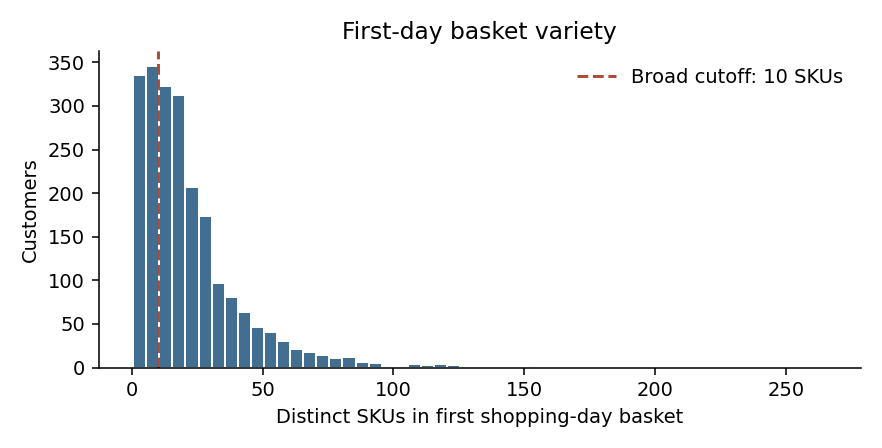

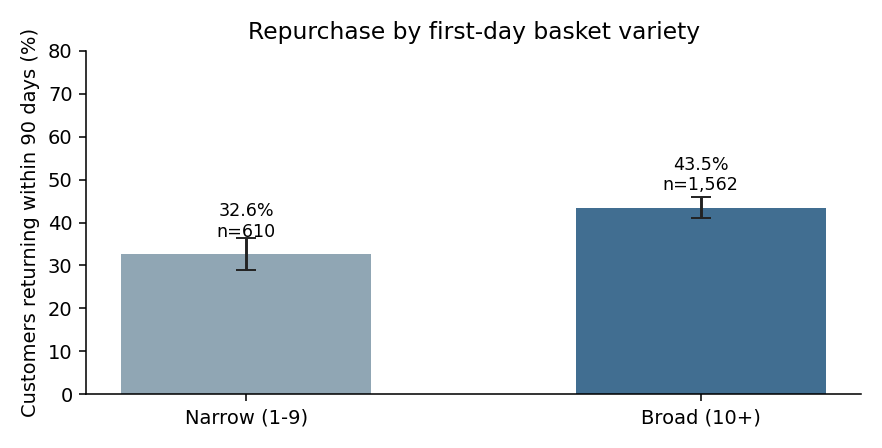

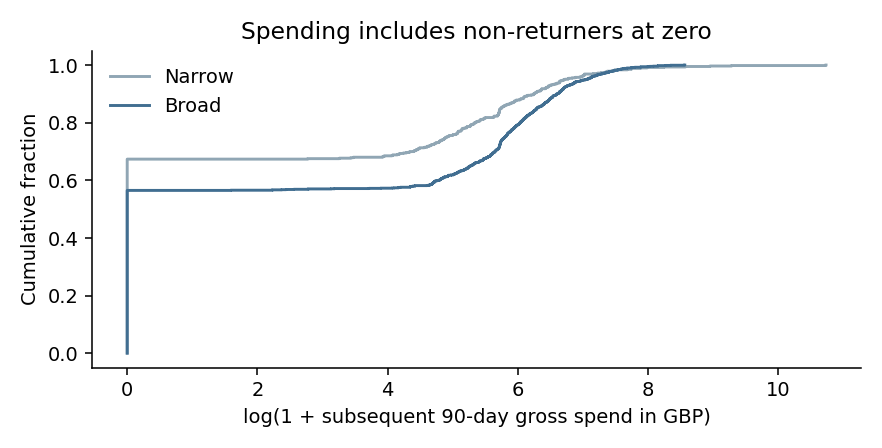

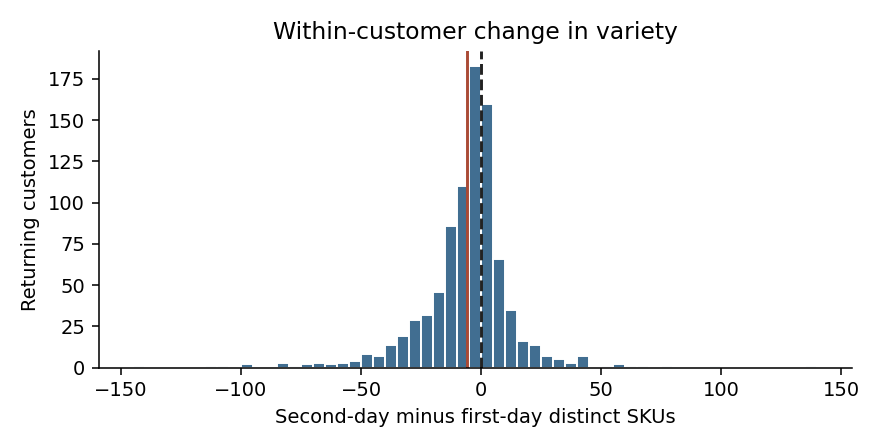

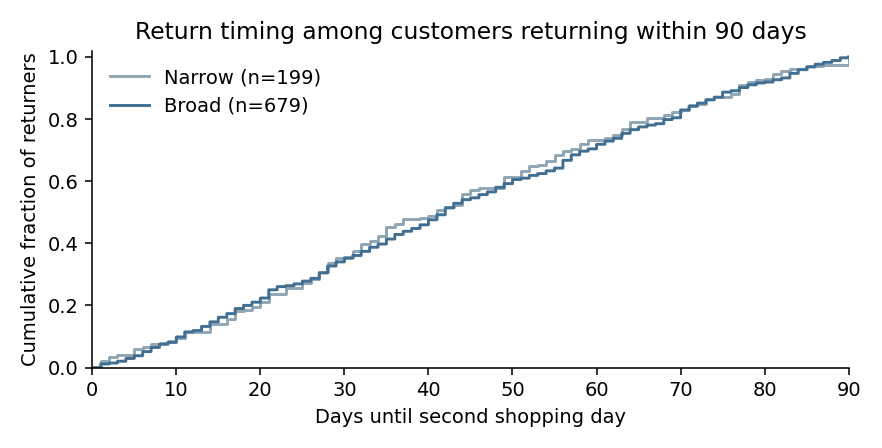

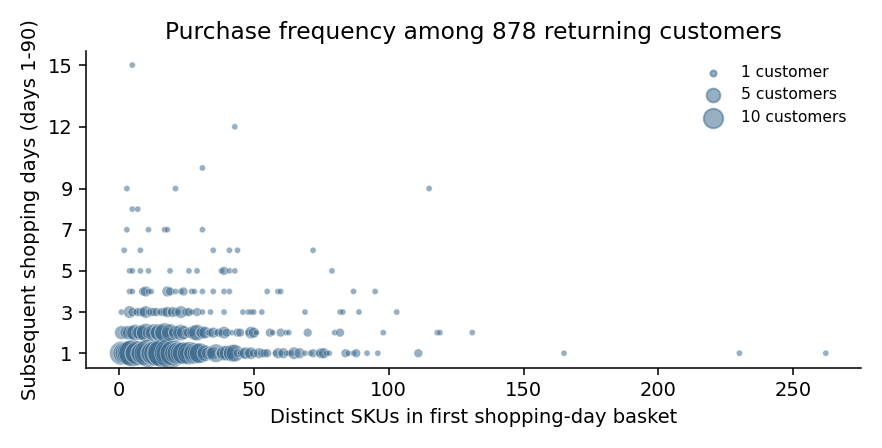

In [8]:
# Display the six generated figures inline.
from IPython.display import display, Image
for image_path in sorted((ROOT / 'figures').glob('*.png')):
    display(Image(filename=str(image_path)))


## Interpretation

T1-T3 retain their original effects and remain significant after Holm adjustment
across all five tests. The unadjusted return-probability gap is +10.85 percentage
points; adjustment for initial spending, units and month leaves its incremental
association uncertain. Higher mean log(1+spend) does not establish higher
arithmetic revenue. Returning customers have about 6.09 fewer SKUs on the second
shopping day.

T4 estimates a broad-minus-narrow return gap of +0.770 days (95% CI -3.076 to
4.617); T5 estimates Spearman rho=0.0236 (bootstrap CI -0.0413 to 0.0890).
Neither added test rejects its null after the five-test Holm adjustment. These
are conditional findings among observed returners, not proof of equality or
causal effects. The plan records the staged addition of T4/T5 before their tests.

The report uses the professor's supplied LaTeX template. Its numerical macros
are regenerated from the same analysis. Compile `report.tex` to update the PDF;
executing this notebook regenerates data, results and figures, but does not
compile LaTeX or publish anything to GitHub.
